# NewsBot Intelligence System
**Benjamin LaCount II · ITAI 2373 · Solo midterm · October 17, 2026**

[Repository](https://github.com/MarineMaaan/ITAI2373-NewsBot-Midterm) ·
[BBC dataset](https://www.kaggle.com/competitions/learn-ai-bbc/data)

## 1. Business context and run instructions
NewsBot helps a small media desk route articles, identify entities and relationships,
and flag tone for human review. The intended user is an editor or research analyst;
value comes from reducing repetitive sorting, with a human checking uncertain cases.
Benjamin's related interest is categorizing his studio's game reviews. That requires
new review data, a review-specific label scheme and separate validation; BBC news
accuracy does not establish review-analysis accuracy.

**Run in Google Colab free tier, CPU.** Runtime → Run all. The next setup cell installs
small libraries and the small English spaCy model. Download and extract **BBC News Train.csv**
from Kaggle yourself, then select that file in the explicit upload cell. No credentials,
automatic news download, dataset bundle, or sample-data fallback is used.
The supplied Test.csv is unlabeled and the sample solution is not ground truth.
Instructor approval for BBC was confirmed by the student.

BBC has **business, entertainment, politics, sport, tech**, not health. Do not infer
health support. Original case and punctuation are preserved for parsing; lemmas feed
the classifier. BBC text is largely lowercased, which weakens case-sensitive NER.

All eight modules and the four non-video bonus extensions are included. No team
name/number or video is used. The extra-credit list exceeds the stated 15-point cap;
the instructor determines the awarded total.

In [1]:
import importlib.util, subprocess, sys
from pathlib import Path
IN_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
if IN_COLAB:
    packages = ['numpy>=1.26,<3', 'pandas>=2.2,<3', 'scikit-learn>=1.5,<1.8',
                'spacy>=3.8,<3.9', 'nltk>=3.9,<4', 'matplotlib>=3.9,<4',
                'seaborn>=0.13,<0.14', 'gradio>=5,<6']
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *packages])
import spacy, nltk
if not spacy.util.is_package('en_core_web_sm'):
    subprocess.check_call([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'])
assert nltk.download('vader_lexicon', quiet=True), 'NLTK resource download failed; check internet access.'
print('Setup complete. CPU only; no paid APIs or GPU required.')

Setup complete. CPU only; no paid APIs or GPU required.


## Required dataset upload
Download the **labeled training CSV**, not kaggle.json, the test CSV or sample solution.
The notebook deliberately stops if no valid file is supplied. Local reproducibility
uses an explicitly supplied `NEWSBOT_LOCAL_CSV` path; Colab always uses the upload picker.

In [2]:
import os
if IN_COLAB:
    from google.colab import files
    print('Upload BBC News Train.csv downloaded from Kaggle:')
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Upload exactly one labeled BBC training CSV.')
    filename, payload = next(iter(uploaded.items()))
    if not filename.lower().endswith('.csv'):
        raise ValueError('Please extract the download and upload the training CSV.')
else:
    local_path = os.environ.get('NEWSBOT_LOCAL_CSV')
    if not local_path:
        raise RuntimeError('Open in Colab to upload, or explicitly set NEWSBOT_LOCAL_CSV for local execution.')
    payload = Path(local_path).read_bytes()
print('File received; validation follows.')

File received; validation follows.


## Reusable implementation
These embedded modules make the notebook runnable by itself in Colab. The same
source is available as readable `.py` files in the repository.

In [3]:
Path('newsbot.py').write_text('"""NewsBot: bounded, reproducible news intelligence for BBC\'s five labels.\n\nAll learned transforms belong inside CV pipelines. Original text is kept for\nlinguistic analysis; cleaned lemmas feed the classifier. No dataset is downloaded.\n"""\nfrom __future__ import annotations\n\nimport hashlib\nimport html\nimport io\nimport json\nimport re\nimport time\nimport unicodedata\nfrom collections import Counter\nfrom itertools import combinations\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport spacy\nfrom nltk.sentiment import SentimentIntensityAnalyzer\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.feature_selection import SelectPercentile, chi2\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import accuracy_score, classification_report, f1_score\nfrom sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split\nfrom sklearn.naive_bayes import MultinomialNB\nfrom sklearn.pipeline import FeatureUnion, Pipeline\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.svm import LinearSVC\n\nSEED = 42\nCATEGORIES = [\'business\', \'entertainment\', \'politics\', \'sport\', \'tech\']\nENTITY_LABELS = {\'PERSON\', \'ORG\', \'GPE\', \'DATE\', \'MONEY\'}\n# Transparent instructional lexicon: coverage counts, not validated emotion probabilities.\nEMOTIONS = {\n    \'joy\': {\'win\', \'victory\', \'celebrate\', \'happy\', \'success\', \'delight\', \'proud\'},\n    \'fear\': {\'fear\', \'threat\', \'risk\', \'danger\', \'worry\', \'crisis\', \'terror\'},\n    \'anger\': {\'anger\', \'angry\', \'protest\', \'outrage\', \'furious\', \'dispute\'},\n    \'sadness\': {\'death\', \'die\', \'loss\', \'sad\', \'tragedy\', \'grief\', \'mourn\'},\n}\n\n\ndef clean_text(value):\n    """Normalize markup/Unicode/URLs without destroying casing, dates or money."""\n    if value is None or (isinstance(value, float) and np.isnan(value)):\n        return \'\'\n    text = unicodedata.normalize(\'NFKC\', html.unescape(str(value)))\n    text = re.sub(r\'<[^>]*>\', \' \', text)\n    text = re.sub(r\'https?://\\S+|www\\.\\S+|\\b\\S+@\\S+\\.\\S+\', \' \', text)\n    return re.sub(r\'\\s+\', \' \', text).strip()\n\n\ndef read_dataset(payload: bytes):\n    """Validate uploaded labeled BBC CSV; reject unlabeled competition test data.\n\n    Canonical duplicate texts are removed BEFORE splitting. Conflicting labels\n    fail loudly. English is a source property plus a heuristic screen, not a\n    proven language detector. CSV bytes and audit counts are retained as metadata.\n    """\n    df = pd.read_csv(io.BytesIO(payload))\n    df.columns = [str(c).strip().lower() for c in df.columns]\n    df = df.rename(columns={\'content\': \'text\', \'articleid\': \'article_id\'})\n    if not {\'text\', \'category\'}.issubset(df.columns):\n        raise ValueError(\'Upload BBC News Train.csv with Text and Category columns; Test.csv has no labels.\')\n    audit = {\'sha256\': hashlib.sha256(payload).hexdigest(), \'uploaded_rows\': len(df)}\n    df = df.dropna(subset=[\'text\', \'category\']).copy()\n    audit[\'missing_removed\'] = audit[\'uploaded_rows\'] - len(df)\n    df[\'text\'] = df[\'text\'].map(clean_text)\n    df[\'category\'] = df[\'category\'].astype(str).str.strip().str.lower().replace({\'sports\': \'sport\', \'technology\': \'tech\'})\n    unknown = set(df.category) - set(CATEGORIES)\n    if unknown:\n        raise ValueError(f\'Unexpected BBC labels: {sorted(unknown)}\')\n    df[\'canonical\'] = df.text.str.casefold().str.replace(r\'[^\\w]+\', \' \', regex=True).str.strip()\n    if (df.groupby(\'canonical\').category.nunique() > 1).any():\n        raise ValueError(\'Duplicate text has conflicting labels; resolve the source before training.\')\n    before = len(df)\n    df = df.drop_duplicates(\'canonical\')\n    audit[\'duplicates_removed\'] = before - len(df)\n    substantial = df.text.str.split().str.len().ge(40)\n    # Detect grossly incompatible inputs; source provenance supplies language assurance.\n    english_screen = df.text.str.lower().str.contains(r\'\\b(?:the|and|of|to|in|was|is|for)\\b\', regex=True)\n    audit[\'short_or_language_screen_removed\'] = int((~(substantial & english_screen)).sum())\n    df = df[substantial & english_screen].copy()\n    if df.category.nunique() < 4 or len(df) < 500:\n        raise ValueError(\'Need at least 500 substantial English articles across four BBC categories.\')\n    if len(df) > 2000:\n        df, _ = train_test_split(df, train_size=2000, stratify=df.category, random_state=SEED)\n    if df.category.value_counts().min() < 10:\n        raise ValueError(\'Each category needs at least ten valid articles for stratified evaluation.\')\n    df = df.reset_index(drop=True)\n    df[\'row_id\'] = np.arange(len(df))\n    audit[\'retained_rows\'] = len(df)\n    audit[\'category_counts\'] = df.category.value_counts().sort_index().to_dict()\n    audit[\'uppercase_letter_fraction\'] = sum(c.isupper() for t in df.text for c in t) / max(1, sum(c.isalpha() for t in df.text for c in t))\n    return df, audit\n\n\ndef doc_features(doc, sia):\n    tokens = [t for t in doc if not t.is_space and not t.is_punct]\n    n = max(1, len(tokens))\n    lemmas = [t.lemma_.lower() for t in tokens if t.is_alpha and not t.is_stop and len(t.lemma_) > 1]\n    pos = Counter(t.pos_ for t in tokens)\n    emotion = {k: sum(t.lemma_.lower() in words for t in tokens) for k, words in EMOTIONS.items()}\n    dominant = max(emotion, key=emotion.get) if max(emotion.values()) else \'unmarked\'\n    compound = sia.polarity_scores(doc.text)[\'compound\']\n    syntax = {\n        \'sentence_length\': len(tokens) / max(1, len(list(doc.sents))),\n        \'dependency_distance\': np.mean([abs(t.i - t.head.i) for t in tokens]) if tokens else 0,\n        \'passive_rate\': sum(t.dep_ in {\'auxpass\', \'nsubjpass\'} for t in tokens) / n,\n        \'clause_rate\': sum(t.dep_ in {\'ccomp\', \'xcomp\', \'advcl\', \'relcl\'} for t in tokens) / n,\n    }\n    relations = []\n    for verb in doc:\n        if verb.pos_ != \'VERB\':\n            continue\n        subjects = [t for t in verb.children if t.dep_ in {\'nsubj\', \'nsubjpass\'}]\n        objects = [t for t in verb.children if t.dep_ in {\'dobj\', \'obj\', \'attr\'}]\n        agents = [c for t in verb.children if t.dep_ == \'agent\' for c in t.children if c.dep_ == \'pobj\']\n        passive = any(t.dep_ == \'nsubjpass\' for t in subjects)\n        for subject in subjects:\n            relations.append({\'agent\': \' \'.join(t.text for t in agents) if passive else subject.text,\n                              \'action\': verb.lemma_, \'patient\': subject.text if passive else \' \'.join(t.text for t in objects),\n                              \'negated\': any(t.dep_ == \'neg\' for t in verb.children), \'passive\': passive})\n    entities = [{\'text\': e.text, \'label\': e.label_, \'start\': e.start_char, \'end\': e.end_char} for e in doc.ents if e.label_ in ENTITY_LABELS]\n    pairs = Counter()\n    for sentence in doc.sents:\n        names = sorted({e.text.casefold() for e in sentence.ents if e.label_ in ENTITY_LABELS})\n        pairs.update(combinations(names[:20], 2))\n    return {\'processed\': \' \'.join(lemmas), \'pos\': {k: v/n for k,v in pos.items()},\n            \'patterns\': dict(Counter(f\'{a.pos_}-{b.pos_}\' for a,b in zip(tokens, tokens[1:])).most_common(8)),\n            \'syntax\': syntax, \'sentiment\': compound,\n            \'sentiment_label\': \'positive\' if compound >= .05 else \'negative\' if compound <= -.05 else \'neutral\',\n            \'emotions\': emotion, \'emotion\': dominant, \'entities\': entities, \'relations\': relations[:20],\n            \'pairs\': [{\'source\': a, \'target\': b, \'count\': int(c)} for (a,b),c in pairs.items()]}\n\n\ndef enrich(df, nlp, sia):\n    """Parse in batches; dataset is capped at 2,000, documents at 100,000 chars."""\n    if df.text.str.len().max() > 100_000:\n        raise ValueError(\'Article exceeds the 100,000-character resource limit.\')\n    features = [doc_features(doc, sia) for doc in nlp.pipe(df.text, batch_size=24)]\n    result = df.copy()\n    for key in features[0]:\n        result[key] = [f[key] for f in features]\n    return result\n\n\nclass SyntaxFeatures(BaseEstimator, TransformerMixin):\n    """Nonnegative, per-document grammar features; scaling is fitted per fold."""\n    def fit(self, X, y=None):\n        return self\n\n    def transform(self, X):\n        return np.array([[*row[\'syntax\'].values(), *[row[\'pos\'].get(p,0) for p in [\'NOUN\',\'VERB\',\'ADJ\',\'PROPN\',\'NUM\']]] for row in X])\n\n\nclass TextField(BaseEstimator, TransformerMixin):\n    def fit(self, X, y=None):\n        return self\n\n    def transform(self, X):\n        return [row[\'processed\'] for row in X]\n\n\ndef text_pipeline(model):\n    return Pipeline([(\'text\', TextField()), (\'tfidf\', TfidfVectorizer(max_features=10000, min_df=2, max_df=.95, sublinear_tf=True)),\n                     (\'select\', SelectPercentile(chi2, percentile=100)), (\'model\', model)])\n\n\ndef hybrid_pipeline():\n    return Pipeline([(\'features\', FeatureUnion([\n        (\'lexical\', Pipeline([(\'text\', TextField()), (\'tfidf\', TfidfVectorizer(max_features=10000, min_df=2, max_df=.95, sublinear_tf=True))])),\n        (\'grammar\', Pipeline([(\'extract\', SyntaxFeatures()), (\'scale\', StandardScaler(with_mean=False))]))])),\n        (\'model\', LogisticRegression(max_iter=1500, C=2, random_state=SEED))])\n\n\ndef make_splits(df):\n    train, rest = train_test_split(np.arange(len(df)), test_size=.30, stratify=df.category, random_state=SEED)\n    val, test = train_test_split(rest, test_size=.5, stratify=df.iloc[rest].category, random_state=SEED)\n    assert not (set(train)&set(test) or set(train)&set(val) or set(val)&set(test))\n    return train, val, test\n\n\ndef fit_models(df, splits):\n    """Tune on train CV only. Validation tunes review threshold; test is untouched."""\n    tr, va, te = splits\n    records = df.to_dict(\'records\')\n    X = [records[i] for i in tr]\n    y = df.iloc[tr].category.to_numpy()\n    cv = StratifiedKFold(3, shuffle=True, random_state=SEED)\n    models = {\n        \'Naive Bayes\': (text_pipeline(MultinomialNB()), {\'model__alpha\':[.5,1.0]}),\n        \'Logistic regression\': (text_pipeline(LogisticRegression(max_iter=1500, random_state=SEED)), {\'model__C\':[1,2]}),\n        \'Linear SVM\': (text_pipeline(LinearSVC(random_state=SEED)), {\'model__C\':[.5,1]}),\n    }\n    fitted, rows = {}, []\n    for name,(pipe,params) in models.items():\n        params.update({\'tfidf__ngram_range\':[(1,1),(1,2)], \'select__percentile\':[75,100]})\n        start = time.perf_counter()\n        search = GridSearchCV(pipe, params, scoring=\'f1_macro\', cv=cv, n_jobs=1, error_score=\'raise\')\n        search.fit(X,y)\n        fitted[name] = search.best_estimator_\n        rows.append({\'model\':name,\'cv_macro_f1\':search.best_score_, \'cv_std\':search.cv_results_[\'std_test_score\'][search.best_index_],\n                     \'seconds\':time.perf_counter()-start, \'parameters\':str(search.best_params_)})\n        print(f\'{name}: CV macro-F1 {search.best_score_:.4f}\', flush=True)\n    table = pd.DataFrame(rows).sort_values(\'cv_macro_f1\', ascending=False)\n    selected = table.iloc[0][\'model\']\n    return fitted, table, selected\n\n\ndef score_models(df, splits, fitted):\n    te = splits[2]\n    X = df.iloc[te].to_dict(\'records\')\n    y = df.iloc[te].category.to_numpy()\n    rows, reports, predictions = [], {}, {}\n    for name, model in fitted.items():\n        pred = model.predict(X)\n        rows.append({\'model\':name,\'accuracy\':accuracy_score(y,pred),\'macro_f1\':f1_score(y,pred,average=\'macro\'), \'weighted_f1\':f1_score(y,pred,average=\'weighted\')})\n        reports[name] = classification_report(y,pred,output_dict=True,zero_division=0)\n        predictions[name] = pred\n    return pd.DataFrame(rows), reports, predictions\n\n\ndef paired_bootstrap(y, a, b, repeats=500):\n    rng = np.random.default_rng(SEED)\n    classes = np.unique(y)\n    differences = []\n    for _ in range(repeats):\n        idx = np.concatenate([rng.choice(np.flatnonzero(y==c), size=sum(y==c), replace=True) for c in classes])\n        differences.append(f1_score(y[idx], b[idx], average=\'macro\') - f1_score(y[idx], a[idx], average=\'macro\'))\n    return [float(x) for x in np.quantile(differences,[.025,.975])]\n\n\ndef research_experiment(df, splits):\n    """Predeclared ablation: identical LR, unigram TF-IDF, with/without grammar."""\n    tr,va,te = splits\n    base = text_pipeline(LogisticRegression(C=2,max_iter=1500,random_state=SEED))\n    hybrid = hybrid_pipeline()\n    Xtr = df.iloc[tr].to_dict(\'records\')\n    ytr = df.iloc[tr].category.to_numpy()\n    Xte = df.iloc[te].to_dict(\'records\')\n    yte = df.iloc[te].category.to_numpy()\n    base.fit(Xtr,ytr)\n    hybrid.fit(Xtr,ytr)\n    a,b = base.predict(Xte), hybrid.predict(Xte)\n    # A label-preserving stress test, not a second natural test set.\n    masked = []\n    for row in Xte:\n        copy = dict(row)\n        words = {w.lower() for e in row[\'entities\'] for w in e[\'text\'].split()}\n        copy[\'processed\'] = \' \'.join(w for w in row[\'processed\'].split() if w not in words)\n        masked.append(copy)\n    return {\'hypothesis\':\'Adding grammar improves macro-F1 beyond lexical features.\',\n            \'baseline_f1\':f1_score(yte,a,average=\'macro\'), \'hybrid_f1\':f1_score(yte,b,average=\'macro\'),\n            \'difference_ci95\':paired_bootstrap(yte,a,b),\n            \'baseline_masked_f1\':f1_score(yte,base.predict(masked),average=\'macro\'),\n            \'hybrid_masked_f1\':f1_score(yte,hybrid.predict(masked),average=\'macro\'),\n            \'caveat\':\'Single split; bootstrap conditions on fitted models. Masked grammar retains original syntax. No claim of academic novelty or causal benefit.\'}\n\n\ndef review_threshold(df, splits, model):\n    """Validation-only margin threshold; margin is not a calibrated probability."""\n    X = df.iloc[splits[1]].to_dict(\'records\')\n    if hasattr(model,\'decision_function\'):\n        scores = model.decision_function(X)\n    else:\n        scores = model.predict_proba(X)\n    ordered = np.sort(scores,axis=1)\n    margins = ordered[:,-1]-ordered[:,-2]\n    threshold = float(np.quantile(margins,.20))\n    return threshold\n\n\ndef analyze_article(text, model, nlp, sia, threshold, custom_ner=None):\n    text = clean_text(text)\n    if len(text.split()) < 8:\n        raise ValueError(\'Please provide at least eight words of article text.\')\n    if len(text) > 100_000:\n        raise ValueError(\'Please keep articles below 100,000 characters.\')\n    row = doc_features(nlp(text),sia)\n    if not row[\'processed\']:\n        raise ValueError(\'No usable English content words were found.\')\n    category = str(model.predict([row])[0])\n    scores = model.decision_function([row]) if hasattr(model,\'decision_function\') else model.predict_proba([row])\n    ordered = np.sort(scores[0])\n    margin = float(ordered[-1]-ordered[-2])\n    row.update({\'predicted_category\':category,\'score_margin\':margin,\'review_required\':bool(margin<threshold),\n                \'scope\':\'Five BBC labels; health and non-English input are outside the trained label space.\'})\n    row[\'custom_entities\'] = [{\'text\':e.text,\'label\':e.label_} for e in custom_ner(text).ents] if custom_ner else []\n    return row\n\n\ndef create_dashboard(model,nlp,sia,threshold,custom_ner=None):\n    import gradio as gr\n    def predict(text):\n        try:\n            result = analyze_article(text,model,nlp,sia,threshold,custom_ner)\n            return (f"{result[\'predicted_category\'].title()} | sentiment: {result[\'sentiment_label\']} | "\n                    f"review: {result[\'review_required\']}", result)\n        except ValueError as exc:\n            raise gr.Error(str(exc)) from exc\n    return gr.Interface(fn=predict, inputs=gr.Textbox(lines=8,label=\'English news article\'),\n                        outputs=[gr.Textbox(label=\'News desk summary\'),gr.JSON(label=\'Entities, syntax, tone and review evidence\')],\n                        title=\'NewsBot Intelligence Desk\',\n                        description=\'Five BBC categories. VADER tone and emotion cues are heuristic; verify facts and entity links.\',\n                        examples=[["A football club won the league final after its striker scored two goals. The coach praised the team and supporters celebrated the victory at the stadium."],\n                                  ["A software company unveiled a new processor for laptops. Engineers said the chip improves computing speed and battery efficiency. The product will reach computer manufacturers next month."]])\n', encoding='utf-8')
Path('extensions.py').write_text('"""Bonus experiments. Authored evaluation sets are controlled demonstrations.\n\nThey do not establish real-world multilingual accuracy or production NER quality.\n"""\nimport random\nimport re\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport spacy\nfrom sklearn.metrics import accuracy_score, f1_score\nfrom spacy.training import Example\nfrom spacy.util import fix_random_seed, minibatch\n\nfrom newsbot import SEED, doc_features\n\n# Fixed before evaluation. These pairs are original teaching examples, not BBC text.\n# The glossary is an experimental rule-based translation aid, not a translator.\nGLOSSARY = {\n    \'empresa\':\'company\',\'acciones\':\'shares\',\'mercado\':\'market\',\'beneficios\':\'profits\',\'banco\':\'bank\',\n    \'inversores\':\'investors\',\'economia\':\'economy\',\'ventas\':\'sales\',\'crecimiento\':\'growth\',\'precio\':\'price\',\n    \'equipo\':\'team\',\'partido\':\'match\',\'gol\':\'goal\',\'futbol\':\'football\',\'liga\':\'league\',\'jugador\':\'player\',\n    \'entrenador\':\'coach\',\'estadio\':\'stadium\',\'victoria\':\'victory\',\'torneo\':\'tournament\',\n    \'gobierno\':\'government\',\'elecciones\':\'election\',\'ministro\':\'minister\',\'parlamento\':\'parliament\',\'votantes\':\'voters\',\n    \'partido_politico\':\'party\',\'ley\':\'law\',\'politica\':\'policy\',\'presidente\':\'president\',\'votos\':\'votes\',\n    \'pelicula\':\'film\',\'actor\':\'actor\',\'musica\':\'music\',\'cine\':\'cinema\',\'premio\':\'award\',\n    \'cantante\':\'singer\',\'album\':\'album\',\'concierto\':\'concert\',\'actriz\':\'actress\',\'festival\':\'festival\',\n    \'software\':\'software\',\'ordenador\':\'computer\',\'internet\':\'internet\',\'tecnologia\':\'technology\',\'usuarios\':\'users\',\n    \'seguridad\':\'security\',\'procesador\':\'processor\',\'datos\':\'data\',\'red\':\'network\',\'movil\':\'mobile\',\n}\nPAIR_SPECS = {\n    \'business\': [(\'empresa acciones mercado beneficios\',\'company shares market profits\'),\n                 (\'banco inversores economia crecimiento\',\'bank investors economy growth\'),\n                 (\'ventas beneficios empresa precio\',\'sales profits company price\'),\n                 (\'mercado acciones inversores banco\',\'market shares investors bank\'),\n                 (\'economia crecimiento ventas empresa\',\'economy growth sales company\')],\n    \'sport\': [(\'equipo partido gol futbol\',\'team match goal football\'),(\'liga jugador entrenador victoria\',\'league player coach victory\'),\n              (\'estadio futbol equipo torneo\',\'stadium football team tournament\'),(\'jugador gol liga partido\',\'player goal league match\'),\n              (\'entrenador equipo victoria estadio\',\'coach team victory stadium\')],\n    \'politics\': [(\'gobierno elecciones ministro parlamento\',\'government election minister parliament\'),\n                 (\'votantes partido_politico politica votos\',\'voters party policy votes\'),\n                 (\'presidente gobierno ley parlamento\',\'president government law parliament\'),\n                 (\'elecciones votos ministro politica\',\'election votes minister policy\'),\n                 (\'parlamento votantes gobierno presidente\',\'parliament voters government president\')],\n    \'entertainment\': [(\'pelicula actor cine premio\',\'film actor cinema award\'),(\'musica cantante album concierto\',\'music singer album concert\'),\n                      (\'actriz pelicula festival premio\',\'actress film festival award\'),(\'cine actor pelicula festival\',\'cinema actor film festival\'),\n                      (\'album musica cantante premio\',\'album music singer award\')],\n    \'tech\': [(\'software ordenador internet tecnologia\',\'software computer internet technology\'),\n             (\'usuarios seguridad datos red\',\'users security data network\'),(\'procesador ordenador tecnologia software\',\'processor computer technology software\'),\n             (\'movil internet usuarios red\',\'mobile internet users network\'),(\'datos seguridad software tecnologia\',\'data security software technology\')],\n}\n\n\ndef cross_lingual(model,nlp,sia):\n    import unicodedata\n    rows = []\n    def predict(t):\n        return model.predict([doc_features(nlp(t),sia)])[0]\n    for label,pairs in PAIR_SPECS.items():\n        for i,(es,en) in enumerate(pairs):\n            spanish = f\'El informe analiza {es.replace(" ",", ")} en el sector. Los expertos presentan los resultados de una nueva investigacion.\'\n            english = f\'The report examines {en.replace(" ",", ")} in the sector. Experts present the results of a new investigation.\'\n            normalized = \'\'.join(c for c in unicodedata.normalize(\'NFD\',spanish.lower()) if not unicodedata.combining(c))\n            translated = re.sub(r\'\\b\\w+\\b\',lambda m:GLOSSARY.get(m.group(),m.group()),normalized)\n            rows.append({\'pair_id\':f\'{label}-{i}\',\'expected\':label,\'english\':english,\'spanish\':spanish,\n                         \'english_prediction\':predict(english),\'spanish_prediction\':predict(spanish),\'glossary_prediction\':predict(translated)})\n    table = pd.DataFrame(rows)\n    metrics = []\n    for condition,col in [(\'English control\',\'english_prediction\'),(\'Spanish direct\',\'spanish_prediction\'),(\'Spanish with glossary\',\'glossary_prediction\')]:\n        metrics.append({\'condition\':condition,\'accuracy\':accuracy_score(table.expected,table[col]),\'macro_f1\':f1_score(table.expected,table[col],average=\'macro\')})\n    return table,pd.DataFrame(metrics)\n\n\ndef ner_annotations():\n    """Names and sentence frames are disjoint across train/dev/test.\n\n    Two custom newsroom labels; 96 train, 12 dev, 12 test sentences. Offsets are\n    built from exact strings and checked against tokenizer boundaries. Entire\n    outlet/product pairs are held out, avoiding a memorized-name-only evaluation.\n    """\n    names = {\n        \'train\': [(\'Pixel Ledger\',\'Aurora Engine\'),(\'Studio Signal\',\'Prism Console\'),(\'Game Wire\',\'Vertex Toolkit\'),\n                  (\'Render Review\',\'Nova Headset\'),(\'Play Chronicle\',\'Orbit Controller\'),(\'Indie Beacon\',\'Vivid Editor\'),\n                  (\'Quest Tribune\',\'Pulse Handheld\'),(\'Digital Gazette\',\'Helix Runtime\')],\n        \'dev\': [(\'Arcade Observer\',\'Cobalt Platform\'),(\'Frame Bulletin\',\'Ember Compiler\')],\n        \'test\': [(\'Level Dispatch\',\'Nimbus Device\'),(\'Creator Sentinel\',\'Quartz Renderer\')],\n    }\n    templates = {\n        \'train\': [\'{o} reviewed {p} for game developers.\', \'{o} published a report about {p}.\',\n                  \'Developers told {o} that {p} supports their studio.\', \'{p} received an update according to {o}.\',\n                  \'An editor at {o} tested {p} yesterday.\', \'The launch of {p} was covered by {o}.\',\n                  \'{o} compared the performance of {p}.\', \'A journalist from {o} discussed {p} at the conference.\',\n                  \'{p} appeared in a feature from {o}.\', \'{o} interviewed the engineers behind {p}.\',\n                  \'The studio demonstrated {p} to {o}.\', \'{o} reported that {p} will ship next month.\'],\n        \'dev\': [\'A new investigation by {o} examined {p}.\',\'During the briefing, {o} asked about {p}.\',\n                \'Readers of {o} requested a test of {p}.\',\'{p} attracted attention from {o} this week.\',\n                \'The team invited {o} to inspect {p}.\',\'{o} offered an assessment of {p}.\'],\n        \'test\': [\'In an exclusive story, {o} described the release of {p}.\',\'The makers of {p} spoke with {o} after the event.\',\n                 \'Coverage from {o} highlighted changes to {p}.\',\'Following a demonstration of {p}, {o} published its findings.\',\n                 \'{o} announced plans to investigate the design of {p}.\',\'A detailed evaluation of {p} appeared in {o} on Monday.\'],\n    }\n    rows=[]\n    for split,pairs in names.items():\n        for outlet,product in pairs:\n            for template in templates[split]:\n                text=template.format(o=outlet,p=product)\n                entities=[]\n                for entity,label in [(outlet,\'NEWS_OUTLET\'),(product,\'TECH_PRODUCT\')]:\n                    start=text.index(entity)\n                    entities.append((start,start+len(entity),label))\n                rows.append({\'split\':split,\'text\':text,\'entities\':sorted(entities)})\n    return rows\n\n\ndef train_custom_ner(output_dir=\'artifacts/custom_ner\'):\n    fix_random_seed(SEED)\n    rng=random.Random(SEED)\n    rows=ner_annotations()\n    model=spacy.blank(\'en\')\n    ner=model.add_pipe(\'ner\')\n    for label in [\'NEWS_OUTLET\',\'TECH_PRODUCT\']:\n        ner.add_label(label)\n    def examples(split):\n        result=[]\n        for row in rows:\n            if row[\'split\'] != split:\n                continue\n            doc=model.make_doc(row[\'text\'])\n            for a,b,_ in row[\'entities\']:\n                assert doc.char_span(a,b,alignment_mode=\'strict\') is not None\n            result.append(Example.from_dict(doc,{\'entities\':row[\'entities\']}))\n        return result\n    train=examples(\'train\')\n    optimizer=model.initialize(lambda:train)\n    best=-1\n    checkpoint=None\n    history=[]\n    for epoch in range(25):\n        rng.shuffle(train)\n        losses={}\n        for batch in minibatch(train,size=8):\n            model.update(batch,sgd=optimizer,drop=.2,losses=losses)\n        metrics=model.evaluate(examples(\'dev\'))\n        history.append({\'epoch\':epoch+1,\'loss\':losses.get(\'ner\',0),\'dev_f1\':metrics[\'ents_f\']})\n        if metrics[\'ents_f\']>best:\n            best=metrics[\'ents_f\']\n            checkpoint=model.to_bytes()\n    model.from_bytes(checkpoint)\n    test=model.evaluate(examples(\'test\'))\n    # Untrained domain-label baseline: emits no custom entities.\n    summary={\'train_sentences\':96,\'dev_sentences\':12,\'test_sentences\':12,\n             \'test_precision\':test[\'ents_p\'],\'test_recall\':test[\'ents_r\'],\'test_f1\':test[\'ents_f\'],\n             \'per_label\':test[\'ents_per_type\'],\'no_custom_entity_baseline_f1\':0.0,\n             \'selected_epoch\':next(r[\'epoch\'] for r in history if r[\'dev_f1\']==best),\n             \'limitation\':\'Authored synthetic sentences, two unseen name pairs and six unseen frames; no manually annotated BBC NER test set.\'}\n    Path(output_dir).mkdir(parents=True, exist_ok=True)\n    model.to_disk(output_dir)\n    predictions=[]\n    for row in rows:\n        if row[\'split\']==\'test\':\n            pred=model(row[\'text\'])\n            predictions.append({\'text\':row[\'text\'],\'gold\':row[\'entities\'],\'predicted\':[(e.start_char,e.end_char,e.label_) for e in pred.ents]})\n    return model,summary,pd.DataFrame(history),rows,predictions\n', encoding='utf-8')
print('Reusable modules ready.')

Reusable modules ready.


,Dataset audit
sha256,f56a65dab2ea728505a639d2186a2b2f1c0939f28e8e89...
uploaded_rows,1490
missing_removed,0
duplicates_removed,52
short_or_language_screen_removed,0
retained_rows,1438
category_counts,"{'business': 334, 'entertainment': 263, 'polit..."
uppercase_letter_fraction,0.0


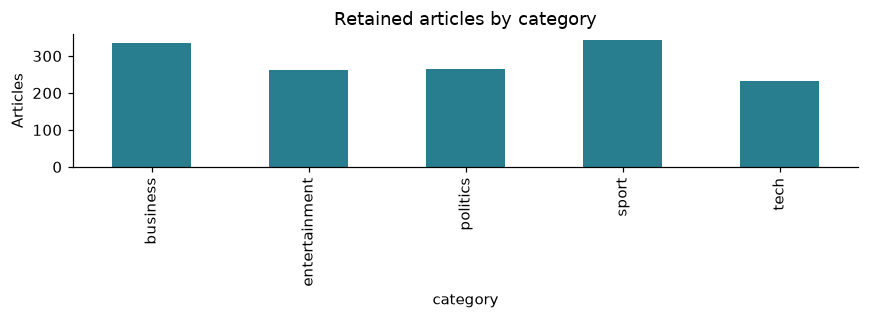

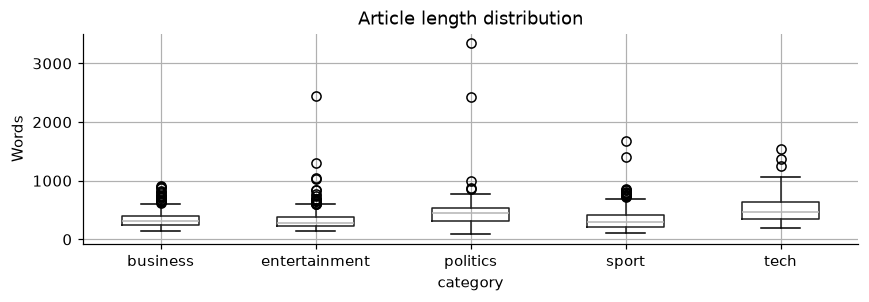

In [4]:
import json, time, platform, importlib.metadata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, accuracy_score
from newsbot import *
from extensions import cross_lingual, train_custom_ner
START = time.perf_counter()
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
nlp = spacy.load('en_core_web_sm')
sia = SentimentIntensityAnalyzer()
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / f'{name}.png', bbox_inches='tight'); plt.show(); plt.close()
df, audit = read_dataset(payload)
display(pd.Series(audit, name='Dataset audit').to_frame())
assert 500 <= len(df) <= 2000 and df.category.nunique() >= 4
df.category.value_counts().sort_index().plot.bar(color='#287d8e', figsize=(8,3))
plt.ylabel('Articles'); plt.title('Retained articles by category'); savefig('01_category_distribution')
df.assign(words=df.text.str.split().str.len()).boxplot(column='words', by='category', figsize=(8,3))
plt.suptitle(''); plt.title('Article length distribution'); plt.ylabel('Words'); savefig('02_article_lengths')

## 2. Preprocessing and data quality
Clean HTML/entities, Unicode, URLs, email and whitespace. spaCy tokenizes and
lemmatizes, removes stop words and punctuation for lexical features. Original
normalized text remains available for POS, dependencies, NER and sentiment, so a
money amount or negation is not destroyed before those tasks. Exact canonical
duplicates are removed before splitting; near duplicates remain a possible risk.
English provenance comes from the selected BBC source plus a lightweight screen,
not a validated language detector. No fabricated titles, dates or sources are added.

In [5]:
df = enrich(df,nlp,sia)
assert df.processed.str.len().gt(0).all()
splits = make_splits(df)
split_names = np.full(len(df),'',dtype=object)
for label,idx in zip(['train','validation','test'],splits): split_names[idx]=label
df['split']=split_names
display(df.groupby(['split','category']).size().unstack(fill_value=0))
before = df.text.str.split().str.len().mean(); after = df.processed.str.split().str.len().mean()
print(f'Mean tokens: before {before:.1f}; after {after:.1f}. Reduction {(1-after/before):.1%}.')
print(f'Preserved uppercase letter fraction: {audit["uppercase_letter_fraction"]:.3%}. Low case coverage limits NER.')
df[['row_id','category','split']].to_csv(OUT/'split_manifest.csv',index=False)

category,business,entertainment,politics,sport,tech
split,,,,,
test,50,40,40,51,35
train,234,184,186,239,163
validation,50,39,40,52,35


Mean tokens: before 385.4; after 194.7. Reduction 49.5%.
Preserved uppercase letter fraction: 0.000%. Low case coverage limits NER.


## 3 & 7. TF-IDF, model comparison and optimization
Fit TF-IDF and chi-squared feature selection **inside each training fold**.
Three-fold stratified CV searches unigrams versus unigrams+bigrams, 75% versus
100% features, and two classifier settings for each of Naive Bayes, logistic
regression and linear SVM (24 configurations / 72 fold fits). Select the winner
by train CV macro-F1, before inspecting test performance. Train/validation/test
is approximately 70/15/15; validation sets a review threshold only.
This follows [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).

Naive Bayes: CV macro-F1 0.9649


Logistic regression: CV macro-F1 0.9724


Linear SVM: CV macro-F1 0.9764


,model,cv_macro_f1,cv_std,seconds,parameters
2,Linear SVM,0.976406,0.006349,6.724473,"{'model__C': 1, 'select__percentile': 75, 'tfi..."
1,Logistic regression,0.972394,0.005064,9.148174,"{'model__C': 2, 'select__percentile': 75, 'tfi..."
0,Naive Bayes,0.964906,0.002459,6.042664,"{'model__alpha': 0.5, 'select__percentile': 75..."


,model,accuracy,macro_f1,weighted_f1
0,Naive Bayes,0.972222,0.970548,0.972210
1,Logistic regression,0.976852,0.975680,0.976676
2,Linear SVM,0.981481,0.980763,0.981447


Selected by training CV: Linear SVM


,precision,recall,f1-score,support
business,0.9615,1.0000,0.9804,50.0000
entertainment,1.0000,0.9750,0.9873,40.0000
politics,1.0000,0.9500,0.9744,40.0000
sport,0.9808,1.0000,0.9903,51.0000
tech,0.9714,0.9714,0.9714,35.0000
accuracy,0.9815,0.9815,0.9815,0.9815
macro avg,0.9827,0.9793,0.9808,216.0000
weighted avg,0.9819,0.9815,0.9814,216.0000


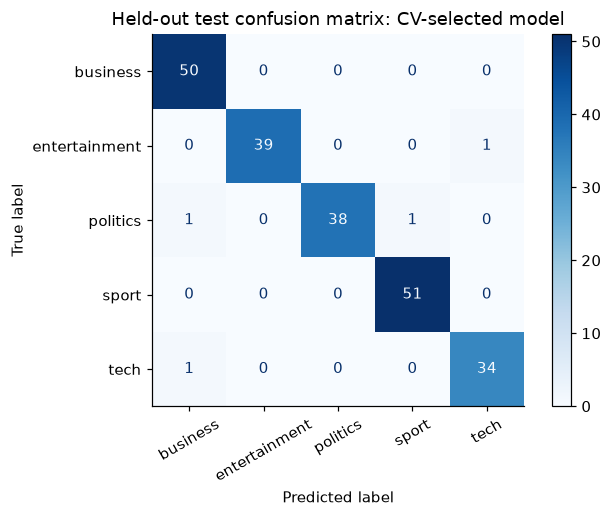

,row_id,actual,predicted
121,247,politics,business
127,335,tech,business
155,5,politics,sport
159,728,entertainment,tech


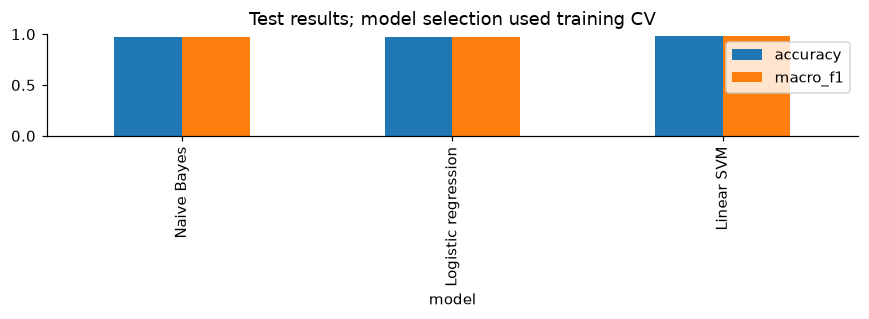

In [6]:
models, cv_table, selected_name = fit_models(df,splits)
display(cv_table)
selected_model = models[selected_name]
threshold = review_threshold(df,splits,selected_model)
test_table, reports, predictions = score_models(df,splits,models)
display(test_table)
print('Selected by training CV:',selected_name)
display(pd.DataFrame(reports[selected_name]).T.round(4))
cv_table.to_csv(OUT/'cv_results.csv',index=False)
test_table.to_csv(OUT/'test_metrics.csv',index=False)
ytest = df.iloc[splits[2]].category.to_numpy()
ConfusionMatrixDisplay.from_predictions(ytest,predictions[selected_name],labels=CATEGORIES,xticks_rotation=30,cmap='Blues')
plt.title('Held-out test confusion matrix: CV-selected model'); savefig('03_confusion_matrix')
errors = pd.DataFrame({'row_id':df.iloc[splits[2]].row_id.to_numpy(),'actual':ytest,'predicted':predictions[selected_name]})
errors = errors[errors.actual != errors.predicted]
display(errors.head(12)); errors.to_csv(OUT/'classification_errors.csv',index=False)
test_table.set_index('model')[['accuracy','macro_f1']].plot.bar(ylim=(0,1),figsize=(8,3))
plt.title('Test results; model selection used training CV'); savefig('04_model_comparison')

Training TF-IDF shape (1006, 10000); sparsity 98.61%


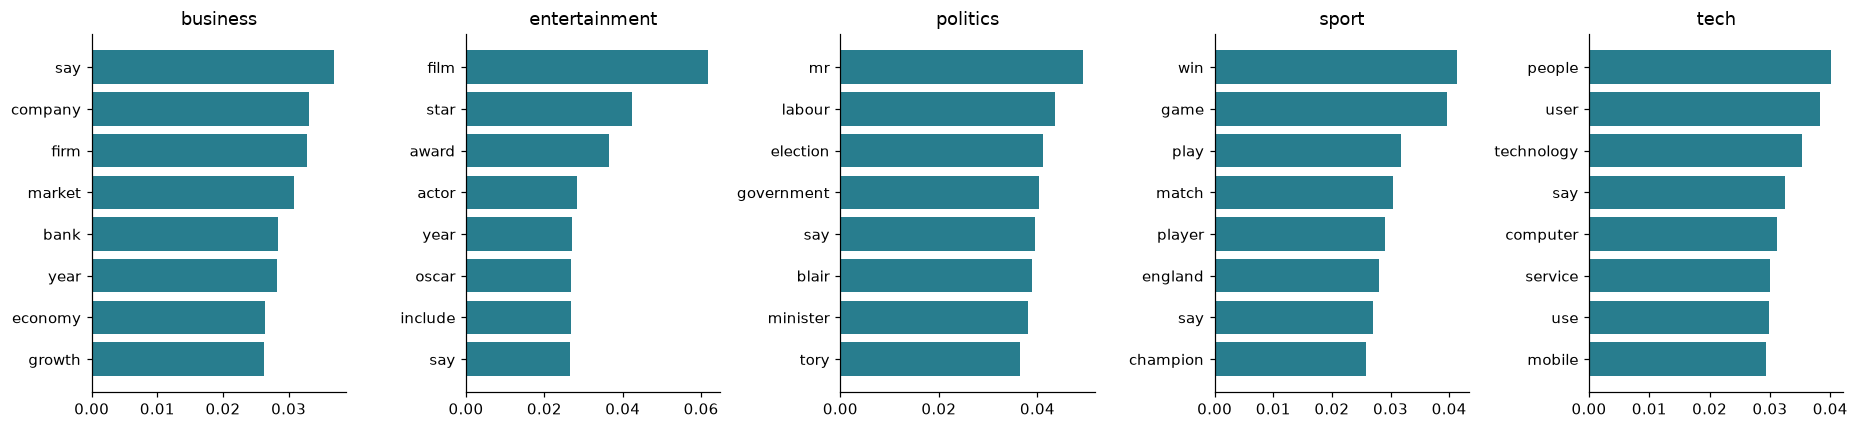

,category,feature,weight
0,business,bank,1.372658
1,business,firm,1.263545
2,business,company,1.174143
3,business,economic,1.096903
4,business,investment,1.014213
10,entertainment,film,1.982416
11,entertainment,star,1.493848
12,entertainment,music,1.311134
13,entertainment,tv,1.087799
14,entertainment,singer,1.074417


Category mean TF-IDF describes prevalence; signed coefficients or NB log-likelihoods describe model association. Neither is causal.


In [7]:
vectorizer = selected_model.named_steps['tfidf']
names = vectorizer.get_feature_names_out()
train = df.iloc[splits[0]]
matrix = vectorizer.transform(train.processed)
print(f'Training TF-IDF shape {matrix.shape}; sparsity {1-matrix.nnz/(matrix.shape[0]*matrix.shape[1]):.2%}')
term_rows=[]
fig,axes=plt.subplots(1,len(CATEGORIES),figsize=(17,4))
for ax,category in zip(axes,CATEGORIES):
    mean=np.asarray(matrix[train.category.to_numpy()==category].mean(axis=0)).ravel()
    idx=mean.argsort()[-8:]
    ax.barh(names[idx],mean[idx],color='#287d8e'); ax.set_title(category)
    term_rows.extend({'category':category,'term':names[i],'mean_tfidf':float(mean[i])} for i in idx)
savefig('05_category_terms'); pd.DataFrame(term_rows).to_csv(OUT/'top_terms.csv',index=False)
selector=selected_model.named_steps['select']; kept=names[selector.get_support()]
classifier=selected_model.named_steps['model']
weights=classifier.coef_ if hasattr(classifier,'coef_') else classifier.feature_log_prob_
importance=[]
for label,row in zip(classifier.classes_,weights):
    for i in row.argsort()[-10:][::-1]: importance.append({'category':label,'feature':kept[i],'weight':float(row[i])})
display(pd.DataFrame(importance).groupby('category').head(5))
pd.DataFrame(importance).to_csv(OUT/'model_feature_weights.csv',index=False)
print('Category mean TF-IDF describes prevalence; signed coefficients or NB log-likelihoods describe model association. Neither is causal.')

## 4. POS and grammatical patterns
Compare per-article POS proportions averaged within category, so long articles do
not dominate. POS bigrams describe local grammatical style. These are descriptive
corpus differences, not evidence of editorial quality or universal category rules.

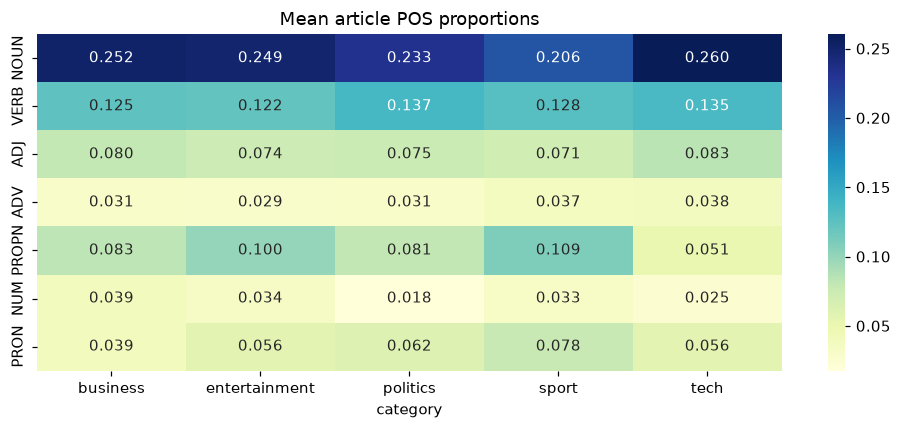

,category,pattern,count
0,business,NOUN-ADP,7276
1,business,DET-NOUN,6215
2,business,ADJ-NOUN,5984
3,business,NOUN-NOUN,5065
4,business,ADP-DET,3808
5,entertainment,NOUN-ADP,5197
6,entertainment,DET-NOUN,5014
7,entertainment,ADJ-NOUN,4185
8,entertainment,NOUN-NOUN,4084
9,entertainment,ADP-DET,3196


In [8]:
pos=pd.DataFrame(df.pos.tolist()).fillna(0); pos['category']=df.category
pos_summary=pos.groupby('category').mean()
major=[p for p in ['NOUN','VERB','ADJ','ADV','PROPN','NUM','PRON'] if p in pos_summary]
plt.figure(figsize=(9,4)); sns.heatmap(pos_summary[major].T,annot=True,fmt='.3f',cmap='YlGnBu')
plt.title('Mean article POS proportions'); savefig('06_pos_patterns')
pos_summary.to_csv(OUT/'pos_by_category.csv')
pattern_rows=[]
for label,group in df.groupby('category'):
    counts=Counter()
    for patterns in group.patterns: counts.update(patterns)
    pattern_rows.extend({'category':label,'pattern':p,'count':n} for p,n in counts.most_common(5))
display(pd.DataFrame(pattern_rows)); pd.DataFrame(pattern_rows).to_csv(OUT/'pos_bigrams.csv',index=False)

## 5. Dependency parsing, semantic roles and syntax features
Extract subject/action/object relations, negation and passive constructions using
dependency labels. Agent and patient fields are **heuristic semantic roles**, not
a trained semantic-role labeling system. Coordination, indirect objects, reported
speech and missing agents are limitations. A missing role stays empty.
Sentence length, dependency distance, clause and passive rates are engineered
features; the research extension evaluates their classification contribution.

,sentence_length,dependency_distance,passive_rate,clause_rate
category,,,,
business,21.978,2.326,0.018,0.057
entertainment,21.549,2.297,0.026,0.054
politics,22.444,2.275,0.025,0.074
sport,19.844,2.366,0.015,0.060
tech,21.641,2.279,0.023,0.068


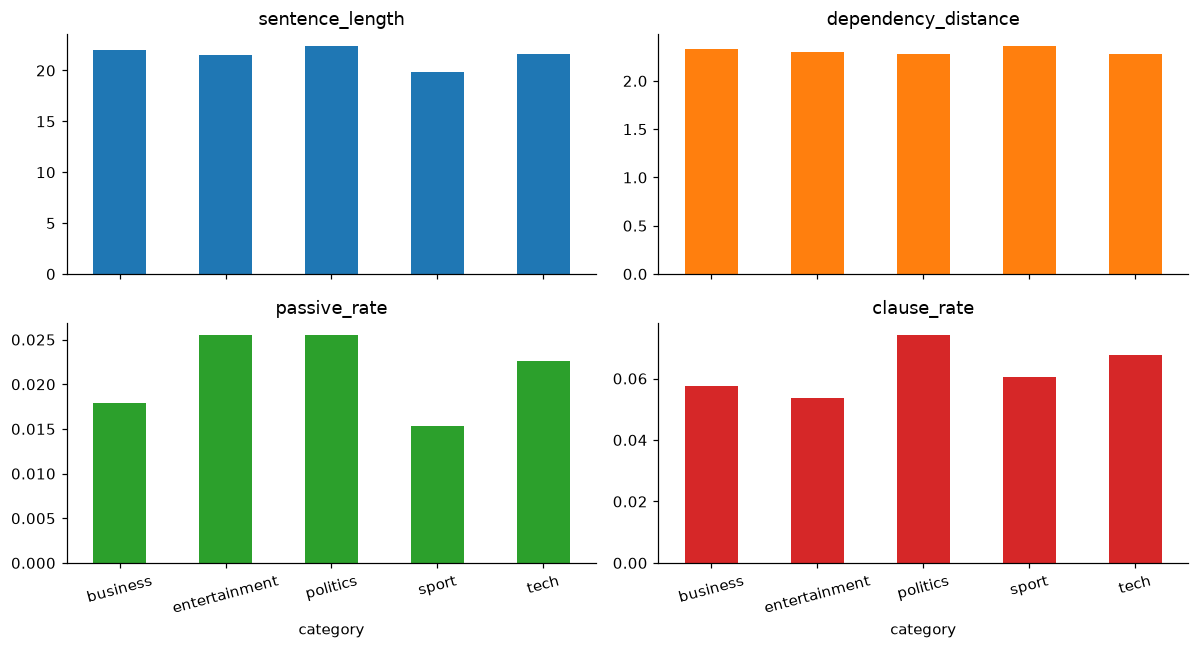

,agent,action,patient,negated,passive
0,studio,release,game,False,False
1,editor,review,game,False,True
2,developer,cancel,launch,True,False


In [9]:
syntax=pd.DataFrame(df.syntax.tolist()); syntax['category']=df.category
syntax_summary=syntax.groupby('category').mean()
display(syntax_summary.round(3)); syntax_summary.to_csv(OUT/'syntax_by_category.csv')
syntax_summary.plot.bar(subplots=True,layout=(2,2),figsize=(11,6),legend=False,rot=15)
savefig('07_syntax_features')
role_demo='The studio released a game. The game was reviewed by the editor. The developer did not cancel the launch.'
display(pd.DataFrame(doc_features(nlp(role_demo),sia)['relations']))

## 6. Sentiment and emotional tone
[NLTK VADER](https://www.nltk.org/api/nltk.sentiment.vader.html) scores the original
text. Compound ≥0.05 is positive, ≤−0.05 negative, otherwise neutral. Scores reflect
language tone, not truth, endorsement or reader opinion. Four small, explicitly
listed lemma lexicons count joy, fear, anger and sadness cues; ties use declaration
order and zero matches become unmarked. This is an interpretable emotion proxy,
not validated emotion classification. BBC has no sentiment/emotion gold labels.

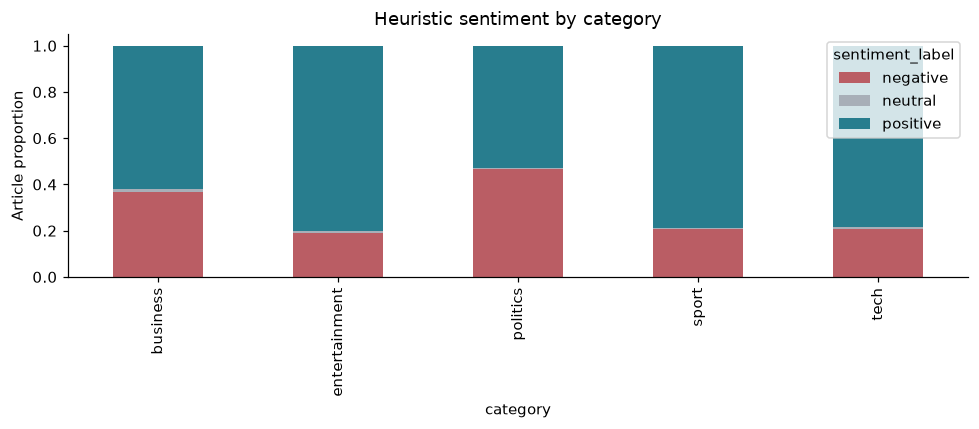

emotion,anger,fear,joy,sadness,unmarked
category,,,,,
business,0.045,0.198,0.111,0.123,0.524
entertainment,0.038,0.057,0.510,0.152,0.243
politics,0.056,0.256,0.248,0.056,0.383
sport,0.009,0.032,0.743,0.015,0.202
tech,0.009,0.197,0.245,0.030,0.519


Emotion lexicons: {'joy': {'win', 'success', 'delight', 'proud', 'happy', 'celebrate', 'victory'}, 'fear': {'crisis', 'threat', 'danger', 'terror', 'worry', 'risk', 'fear'}, 'anger': {'protest', 'furious', 'dispute', 'anger', 'outrage', 'angry'}, 'sadness': {'tragedy', 'sad', 'death', 'mourn', 'loss', 'die', 'grief'}}
Interpret category tone cautiously: reported deaths, sports losses and stock declines may trigger negative vocabulary without opinion.


In [10]:
sentiment_table=pd.crosstab(df.category,df.sentiment_label,normalize='index')
sentiment_table.plot.bar(stacked=True,figsize=(9,4),color=['#ba5d64','#a8afb8','#287d8e'])
plt.ylabel('Article proportion'); plt.title('Heuristic sentiment by category'); savefig('08_sentiment')
sentiment_table.to_csv(OUT/'sentiment_by_category.csv')
emotion_table=pd.crosstab(df.category,df.emotion,normalize='index')
display(emotion_table.round(3)); emotion_table.to_csv(OUT/'emotion_by_category.csv')
print('Emotion lexicons:',EMOTIONS)
print('Interpret category tone cautiously: reported deaths, sports losses and stock declines may trigger negative vocabulary without opinion.')

## 8. Named entities and relationship mapping
Extract PERSON, ORG, GPE, DATE, MONEY with the pretrained English model. Aggregate
frequencies and category patterns. The network uses same-sentence co-occurrence;
an edge means the entities appeared together, not ownership, agreement or causation.
BBC's lowercasing especially limits PERSON/ORG/GPE detection. We do not repair case
by guessing names or claim NER accuracy without gold annotations.

,label,entity,mentions
2549,GPE,us,533
2539,GPE,uk,520
2175,GPE,britain,275
2348,GPE,london,273
346,DATE,2004,253
2252,GPE,france,228
3852,ORG,bbc,227
350,DATE,2005,225
1144,DATE,last year,217
1986,DATE,this year,182


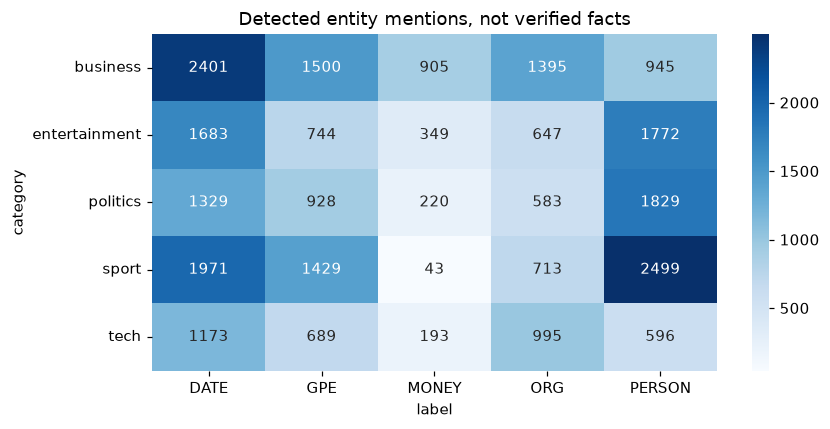

,source,target,sentence_count
0,bbc radio 4 s,today,23
1,france,germany,22
2,uk,us,21
3,england,france,17
4,italy,scotland,16
5,blair,tony blair,16
6,2003,2004,16
7,britain,uk,15
8,2004,us,14
9,eu,uk,14


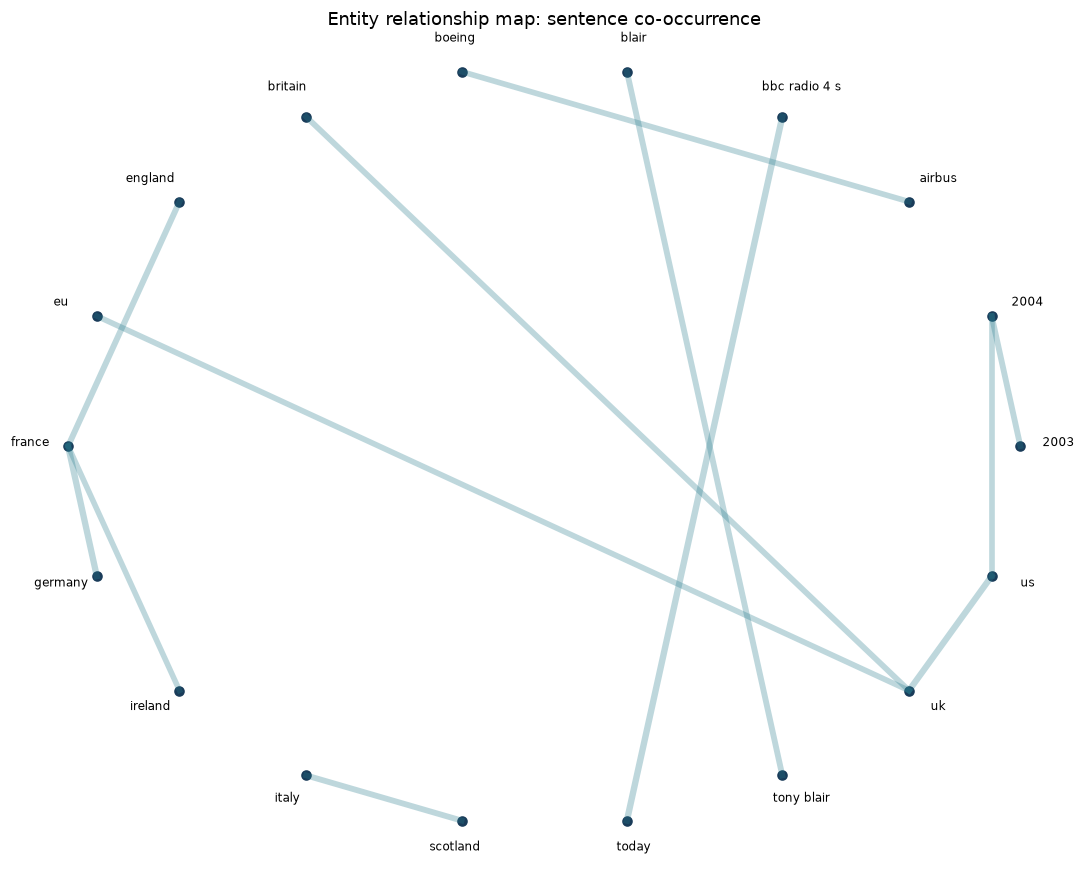

In [11]:
entity_rows=[]; edges=Counter()
for row in df.itertuples():
    entity_rows.extend({'category':row.category,'entity':e['text'].casefold(),'label':e['label']} for e in row.entities)
    for e in row.pairs: edges[(e['source'],e['target'])]+=e['count']
entities=pd.DataFrame(entity_rows,columns=['category','entity','label'])
entity_counts=entities.groupby(['label','entity']).size().rename('mentions').reset_index().sort_values('mentions',ascending=False)
display(entity_counts.groupby('label').head(5)); entity_counts.to_csv(OUT/'entity_frequencies.csv',index=False)
entity_cross=pd.crosstab(entities.category,entities.label).reindex(index=CATEGORIES,columns=sorted(ENTITY_LABELS),fill_value=0)
plt.figure(figsize=(8,4)); sns.heatmap(entity_cross,annot=True,fmt='d',cmap='Blues')
plt.title('Detected entity mentions, not verified facts'); savefig('09_entity_categories')
entity_cross.to_csv(OUT/'entities_by_category.csv')
edge_df=pd.DataFrame([{'source':a,'target':b,'sentence_count':int(n)} for (a,b),n in edges.most_common(20)])
edge_df.to_csv(OUT/'entity_relationships.csv',index=False)
display(edge_df.head(10))
top_edges=list(edges.most_common(12)); nodes=sorted({x for pair,_ in top_edges for x in pair})
if nodes:
    angles=np.linspace(0,2*np.pi,len(nodes),endpoint=False); coords={name:(np.cos(a),np.sin(a)) for name,a in zip(nodes,angles)}
    plt.figure(figsize=(10,8))
    for (a,b),weight in top_edges:
        x,y=coords[a],coords[b]; plt.plot([x[0],y[0]],[x[1],y[1]],alpha=.3,linewidth=1+np.log1p(weight),color='#287d8e')
    for name,(x,y) in coords.items(): plt.scatter(x,y,s=35,color='#193b59'); plt.text(1.08*x,1.08*y,name[:28],ha='center',fontsize=8)
    plt.axis('off'); plt.title('Entity relationship map: sentence co-occurrence'); savefig('10_entity_network')

## Bonus: advanced cross-lingual comparison
Evaluate 25 original paired English/Spanish controlled passages, balanced across
the five labels. Compare English, Spanish directly, and Spanish with a fixed
50-word domain glossary. These short keyword-rich passages intentionally probe
language sensitivity. Their labels/pairs and glossary were specified before
scoring; a glossary matching the probe vocabulary makes this an optimistic
mechanism demonstration, **not general Spanish-language news evaluation**.
The main BBC model is never trained on these passages. Dates are absent from the
BBC CSV, so no publication chronology is invented.

,condition,accuracy,macro_f1
0,English control,0.96,0.959596
1,Spanish direct,0.24,0.135632
2,Spanish with glossary,0.88,0.868132


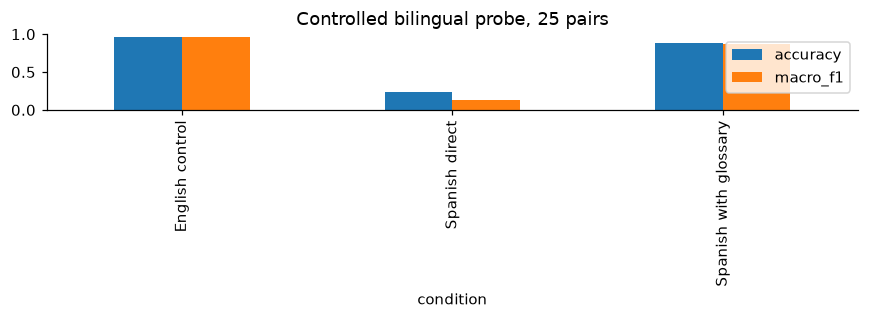

In [12]:
cross_pairs,cross_metrics=cross_lingual(selected_model,nlp,sia)
display(cross_metrics)
cross_pairs.to_csv(OUT/'crosslingual_pairs.csv',index=False); cross_metrics.to_csv(OUT/'crosslingual_metrics.csv',index=False)
cross_metrics.set_index('condition')[['accuracy','macro_f1']].plot.bar(ylim=(0,1),figsize=(8,3))
plt.title('Controlled bilingual probe, 25 pairs'); savefig('11_crosslingual')

## Bonus: custom domain-specific NER training
Train a small spaCy transition-based NER model for **NEWS_OUTLET** and
**TECH_PRODUCT**, motivated by game-industry monitoring. The 96 train, 12 development
and 12 test sentences are original synthetic annotations. Name pairs **and sentence
frames** are disjoint between partitions; offsets are validated. Select the epoch
on development exact-span F1, then score the untouched test set once. Report
precision, recall and per-label F1 against a baseline emitting no custom labels.
This small controlled test does not measure BBC or real game-review NER performance.
[Training reference](https://spacy.io/usage/training).

,Value
train_sentences,96
dev_sentences,12
test_sentences,12
test_precision,0.625
test_recall,0.625
test_f1,0.625
no_custom_entity_baseline_f1,0.0
selected_epoch,5
limitation,"Authored synthetic sentences, two unseen name ..."


,p,r,f
TECH_PRODUCT,0.571429,1.00,0.727273
NEWS_OUTLET,1.000000,0.25,0.400000


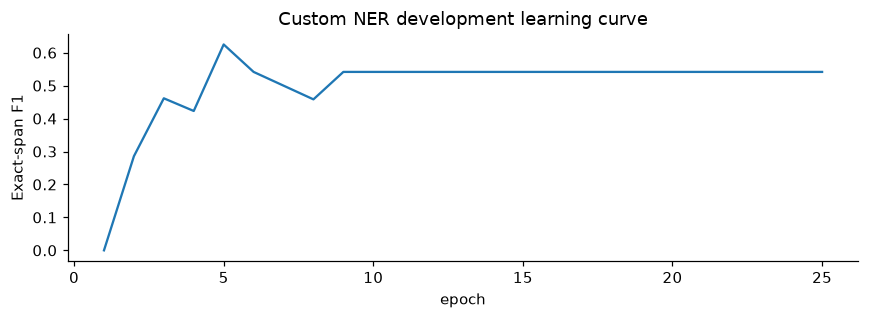

In [13]:
custom_ner,ner_metrics,ner_history,annotations,ner_predictions=train_custom_ner()
display(pd.Series({k:v for k,v in ner_metrics.items() if k != 'per_label'}).to_frame('Value'))
display(pd.DataFrame(ner_metrics['per_label']).T)
(OUT/'custom_ner_annotations.json').write_text(json.dumps(annotations,indent=2),encoding='utf-8')
(OUT/'custom_ner_test_predictions.json').write_text(json.dumps(ner_predictions,indent=2),encoding='utf-8')
ner_history.to_csv(OUT/'custom_ner_learning_curve.csv',index=False)
ner_history.plot(x='epoch',y='dev_f1',figsize=(8,3),legend=False)
plt.ylabel('Exact-span F1'); plt.title('Custom NER development learning curve'); savefig('12_custom_ner')

## Bonus: research extension with ablation and uncertainty
**Question:** do grammar features add value to TF-IDF for BBC category routing?
The project-specific approach combines TF-IDF with normalized POS and dependency
statistics. Compare identical logistic regression (C=2) and unigram vocabulary,
without grammar versus with grammar, on the same untouched test partition.
Report 500 stratified paired-bootstrap resamples for the macro-F1 difference.
A second predeclared stress test masks words from detected entities while retaining
the original grammar measurements. This is a controlled lexical ablation, not an
end-to-end deployment simulation. Negative results are valid findings. This is an
original project experiment, not a claim of research-field novelty.

In [14]:
research=research_experiment(df,splits)
display(pd.Series(research).to_frame('Result'))
ci=research['difference_ci95']
verdict='does not establish an improvement' if ci[0] <= 0 <= ci[1] else ('supports an improvement on this split' if ci[0] > 0 else 'suggests a decline on this split')
print(f'The paired interval {verdict}. Repeat across independent splits and corpora before generalizing.')

,Result
hypothesis,Adding grammar improves macro-F1 beyond lexica...
baseline_f1,0.970608
hybrid_f1,0.929188
difference_ci95,"[-0.0739911401358611, -0.014092334825810354]"
baseline_masked_f1,0.956688
hybrid_masked_f1,0.924837
caveat,Single split; bootstrap conditions on fitted m...


The paired interval suggests a decline on this split. Repeat across independent splits and corpora before generalizing.


## Integrated demonstration: two NEW authored articles
Both examples are original illustrative passages outside the training data. They
show the complete input → preprocessing → category → entities → sentiment → syntax
→ custom NER flow. Predictions are observations, not extra test-accuracy claims.
Low score margins trigger a human-review flag; the margin is not a calibrated
probability and cannot reliably detect out-of-domain text.

In [15]:
new_articles=[
    'A football team won the championship after scoring twice in the final match. The coach praised the players and supporters celebrated at the stadium. The league will announce the next tournament schedule on Monday.',
    'Pixel Ledger reported that a game studio has released Aurora Engine, a software toolkit for computer graphics. Developers said the product improves rendering performance on laptops. The engineering team will publish a security update next month.'
]
demos=[analyze_article(t,selected_model,nlp,sia,threshold,custom_ner) for t in new_articles]
for i,result in enumerate(demos,1):
    print(f'NEW ARTICLE {i}'); display(pd.Series({k:result[k] for k in ['predicted_category','sentiment_label','emotion','review_required','entities','relations','custom_entities']}).to_frame('Result'))
(OUT/'new_article_demonstrations.json').write_text(json.dumps(demos,indent=2),encoding='utf-8')
# Quantify the validation-set review rule on the reserved test set.
test_records=df.iloc[splits[2]].to_dict('records')
scores=selected_model.decision_function(test_records) if hasattr(selected_model,'decision_function') else selected_model.predict_proba(test_records)
ordered=np.sort(scores,axis=1); accepted=(ordered[:,-1]-ordered[:,-2])>=threshold
selective={'test_coverage':float(accepted.mean()),'test_accuracy_when_accepted':float(accuracy_score(ytest[accepted],predictions[selected_name][accepted])) if accepted.any() else None,
           'validation_threshold':threshold,'caveat':'Threshold targets 80% validation coverage; coverage may shift. Margins are not probabilities.'}
display(pd.Series(selective).to_frame('Review policy'))

NEW ARTICLE 1


,Result
predicted_category,sport
sentiment_label,positive
emotion,joy
review_required,False
entities,"[{'text': 'Monday', 'label': 'DATE', 'start': ..."
relations,"[{'agent': 'team', 'action': 'win', 'patient':..."
custom_entities,[]


NEW ARTICLE 2


,Result
predicted_category,tech
sentiment_label,positive
emotion,unmarked
review_required,False
entities,"[{'text': 'Pixel Ledger', 'label': 'PERSON', '..."
relations,"[{'agent': 'Ledger', 'action': 'report', 'pati..."
custom_entities,"[{'text': 'Pixel Ledger', 'label': 'NEWS_OUTLE..."


,Review policy
test_coverage,0.75
test_accuracy_when_accepted,1.0
validation_threshold,1.021647
caveat,Threshold targets 80% validation coverage; cov...


## Bonus: interactive Gradio dashboard
Run this cell to inspect your own article. The interface calls the exact integrated
function used above. In Colab the temporary Gradio share link is needed for browser
access; it expires with the runtime. No hosting subscription or stored dataset is
required. Local execution binds only to loopback. Stop the cell/runtime when done.

In [16]:
dashboard=create_dashboard(selected_model,nlp,sia,threshold,custom_ner)
if os.environ.get('NEWSBOT_SKIP_DASHBOARD') == '1':
    print('Automated run: dashboard constructed; launch is validated separately.')
else:
    dashboard.launch(share=IN_COLAB, inline=True, prevent_thread_lock=True)

D:\HCC BATAI Program\Semester 3\ITAI_2373 NLP\ITAI2373-NewsBot-Midterm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Automated run: dashboard constructed; launch is validated separately.


## Evidence, interpretation and business recommendations
The following summary is computed from this run. Main model selection uses training
CV only. Linguistic tables cover the retained corpus descriptively; their group
labels are never fed into classifier features. No sentiment/standard-NER accuracy
is claimed because the BBC CSV supplies only topic labels.

In [17]:
winner=test_table.set_index('model').loc[selected_name]
high_num=pos_summary['NUM'].idxmax() if 'NUM' in pos_summary else 'unavailable'
tone=df.groupby('category').sentiment.mean().sort_values()
summary=f"""### Findings from this execution
- Retained **{len(df)}** unique substantial articles; split sizes **{[len(i) for i in splits]}**.
- Training CV selected **{selected_name}**. Reserved-test accuracy **{winner.accuracy:.3f}**, macro-F1 **{winner.macro_f1:.3f}**.
- **{high_num}** has the largest mean NUM proportion; structured amounts can help an analyst find quantity-heavy coverage.
- Mean heuristic tone ranges from **{tone.index[0]} ({tone.iloc[0]:.3f})** to **{tone.index[-1]} ({tone.iloc[-1]:.3f})**; this is lexical tone, not verified public opinion.
- Grammar ablation macro-F1: **{research['baseline_f1']:.3f} → {research['hybrid_f1']:.3f}**; difference CI **[{ci[0]:.3f}, {ci[1]:.3f}]**. It {verdict}.
- Custom NER exact-span test F1: **{ner_metrics['test_f1']:.3f}**, on 12 synthetic held-out sentences only.
- Human-review policy accepted **{selective['test_coverage']:.1%}** of held-out articles. Editorial time saved must be measured in a real workflow, not inferred from classifier accuracy.

### Recommendations
Use this as an assisted routing prototype. Review low-margin cases and audit errors by category.
Check entities against original articles; co-occurrence is only a lead for investigation.
For game reviews, collect licensed review text, define relevant labels (bugs, performance,
gameplay, value), annotate sentiment toward the game rather than whole-document tone,
and split by game/source/time to measure generalization. Begin with a small human-reviewed pilot.

### Limits and next experiments
BBC is a historical single-source benchmark. Its labels omit health, its CSV lacks
publication timestamps, and its casing limits NER. Exact deduplication does not remove
all near duplicates. Repeat grouped and temporal tests when metadata is available.
Sentiment/emotions and semantic roles need gold annotations. Bilingual probes and
custom NER data are synthetic and small. No production, fairness or real-time claim is made.
"""
display(Markdown(summary)); (OUT/'findings.md').write_text(summary,encoding='utf-8')
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','spacy','nltk','matplotlib','gradio']}
results={'dataset':audit,'split_sizes':{k:len(v) for k,v in zip(['train','validation','test'],splits)},
         'selected_model':selected_name,'test_metrics':test_table.to_dict('records'),'classification_reports':reports,
         'research':research,'custom_ner':ner_metrics,'crosslingual':cross_metrics.to_dict('records'),
         'review_policy':selective,'versions':versions,'python':platform.python_version(),
         'elapsed_seconds':time.perf_counter()-START,'execution_context':'Local CPU validation; Colab upload path requires browser interaction.' if not IN_COLAB else 'Google Colab CPU'}
(OUT/'results.json').write_text(json.dumps(results,indent=2),encoding='utf-8')
import joblib
Path('artifacts').mkdir(exist_ok=True)
joblib.dump({'model':selected_model,'threshold':threshold},'artifacts/runtime.joblib')
print('Outputs saved to:',OUT.resolve())
if IN_COLAB:
    import shutil
    shutil.make_archive('newsbot_outputs','zip',OUT)
    print('Use the next cell to download the result bundle.')

### Findings from this execution
- Retained **1438** unique substantial articles; split sizes **[1006, 216, 216]**.
- Training CV selected **Linear SVM**. Reserved-test accuracy **0.981**, macro-F1 **0.981**.
- **business** has the largest mean NUM proportion; structured amounts can help an analyst find quantity-heavy coverage.
- Mean heuristic tone ranges from **politics (0.054)** to **entertainment (0.590)**; this is lexical tone, not verified public opinion.
- Grammar ablation macro-F1: **0.971 → 0.929**; difference CI **[-0.074, -0.014]**. It suggests a decline on this split.
- Custom NER exact-span test F1: **0.625**, on 12 synthetic held-out sentences only.
- Human-review policy accepted **75.0%** of held-out articles. Editorial time saved must be measured in a real workflow, not inferred from classifier accuracy.

### Recommendations
Use this as an assisted routing prototype. Review low-margin cases and audit errors by category.
Check entities against original articles; co-occurrence is only a lead for investigation.
For game reviews, collect licensed review text, define relevant labels (bugs, performance,
gameplay, value), annotate sentiment toward the game rather than whole-document tone,
and split by game/source/time to measure generalization. Begin with a small human-reviewed pilot.

### Limits and next experiments
BBC is a historical single-source benchmark. Its labels omit health, its CSV lacks
publication timestamps, and its casing limits NER. Exact deduplication does not remove
all near duplicates. Repeat grouped and temporal tests when metadata is available.
Sentiment/emotions and semantic roles need gold annotations. Bilingual probes and
custom NER data are synthetic and small. No production, fairness or real-time claim is made.


Outputs saved to:

 D:\HCC BATAI Program\Semester 3\ITAI_2373 NLP\ITAI2373-NewsBot-Midterm\ITAI2373-NewsBot-Midterm\outputs


In [18]:
if IN_COLAB:
    from google.colab import files
    files.download('newsbot_outputs.zip')
else:
    print('Local results remain in outputs/.')

Local results remain in outputs/.


## Contributions, reflection and sources
**Solo student:** Benjamin LaCount II. Thought, planning and final quality assurance
remain the student's responsibilities. AI assisted execution, coding, debugging,
documentation and journal drafting. The student supplied the reflection themes:
preprocessing strongly affects final quality; preparation took longer than expected;
future preparation should be more efficient; game-review categorization is a
motivating studio use case. The editable two-page reflective journal accompanies
this notebook. No team members, team number or video are represented.

Sources: [BBC classification competition](https://www.kaggle.com/competitions/learn-ai-bbc/data);
[scikit-learn pipelines/leakage](https://scikit-learn.org/stable/common_pitfalls.html);
[spaCy linguistic features](https://spacy.io/usage/linguistic-features);
[spaCy training](https://spacy.io/usage/training);
[NLTK VADER API](https://www.nltk.org/api/nltk.sentiment.vader.html);
[VADER paper, Hutto & Gilbert 2014](https://ojs.aaai.org/index.php/ICWSM/article/view/14550);
[Gradio interface](https://www.gradio.app/docs/gradio/interface).
The original course starter notebook informed the module sequence. The emotion
lexicons, bilingual probes and custom NER annotations are original instructional
assets authored with AI assistance. Dataset rights remain with their owners.